# Assignment 17: Handling Imbalanced Data – Predicting Credit Card Customer Churn

In this assignment I work with an imbalanced customer churn dataset and compare techniques for handling class imbalance: a baseline Random Forest with no balancing, SMOTE (Synthetic Minority Over-sampling Technique), and class weights. I evaluate them with metrics that suit imbalanced data, not just accuracy.

Why I changed the dataset:
The assignment provides a customer churn file (customer_churn_dataset-testing-master.csv). When I checked it, it was not imbalanced: about 53% of customers stayed and 47% churned. A basic Random Forest also scored 100% accuracy (AUC 1.00) with no balancing at all, so SMOTE and class weights could not show any improvement. Because the goal of this assignment is handling imbalanced data, I used a real, clearly imbalanced churn dataset instead, with the same kind of problem: predicting which customers will leave.

Dataset:
- Name: Credit Card Customers (BankChurners)
- Source: Kaggle (uploaded by Sakshi Goyal) – https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers
- Context: a bank wants to predict which credit card customers are likely to leave (churn), so it can contact them with retention offers before they go
- Target: Attrition_Flag ("Attrited Customer" = churned, "Existing Customer" = stayed), which I will convert to Churn = 1 or 0

Steps I will follow:
1. Import libraries and load the data
2. Check the structure and remove duplicates
3. Split the data into features (X) and target (y), then into training and test sets
4. Explore the training data, including the class distribution and a bar chart
5. Clean and encode the data
6. Train a baseline Random Forest without balancing
7. Apply SMOTE to the training data and retrain the Random Forest
8. Train the Random Forest with class weights
9. Compare all models, including ROC-AUC
10. Write a report

## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, classification_report, confusion_matrix,
                             RocCurveDisplay, PrecisionRecallDisplay)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

pd.set_option("display.max_columns", None)
random_seed = 42

## Why I Changed the Dataset – Checking the Provided File

In [29]:
orig = pd.read_csv("customer_churn_dataset-testing-master.csv")
print("Shape:", orig.shape)
print("Churn distribution:\n", orig["Churn"].value_counts(normalize=True).round(3))

Xo = pd.get_dummies(orig.drop(columns=["CustomerID", "Churn"]), drop_first=True)
Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(Xo, orig["Churn"], test_size=0.2, random_state=random_seed, stratify=orig["Churn"])
rf_o = RandomForestClassifier(random_state=random_seed, n_jobs=-1).fit(Xo_tr, yo_tr)
print("Baseline Random Forest on the provided file - accuracy:", round(accuracy_score(yo_te, rf_o.predict(Xo_te)), 4),
      "| ROC-AUC:", round(roc_auc_score(yo_te, rf_o.predict_proba(Xo_te)[:, 1]), 4))


Shape: (64374, 12)
Churn distribution:
 Churn
0    0.526
1    0.474
Name: proportion, dtype: float64
Baseline Random Forest on the provided file - accuracy: 0.9981 | ROC-AUC: 1.0


## Step 2: Load the Dataset and Check Its Structure

In [2]:
churn = pd.read_csv("BankChurners.csv")

In [3]:
print("Shape:", churn.shape)

Shape: (10127, 23)


In [4]:
display(churn.head())

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [5]:
churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  str    
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                                      

In [6]:
print("\nMissing values:", churn.isnull().sum().sum())


Missing values: 0


In [7]:
print("Duplicate rows:", churn.duplicated().sum())

Duplicate rows: 0


In [8]:
print("Duplicate rows ignoring CLIENTNUM:", churn.drop(columns="CLIENTNUM").duplicated().sum())

Duplicate rows ignoring CLIENTNUM: 0


In [9]:
print("\nTarget values:\n", churn["Attrition_Flag"].value_counts())



Target values:
 Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64


### Interpretation: Dataset Structure

The dataset has 10,127 customers and 23 columns: 17 numeric and 6 text columns (Attrition_Flag, Gender, Education_Level, Marital_Status, Income_Category and Card_Category).

Target:
1,627 customers churned (Attrited Customer) and 8,500 stayed (Existing Customer). Only 16.1% of customers churned, about 1 churner for every 5 customers who stayed, so the dataset is clearly imbalanced. A model that always predicts "stays" would already be 83.9% accurate without finding a single churner, so I will focus on recall, precision, F1-score and ROC-AUC instead of accuracy alone.

Data quality:
- There are no missing values and no duplicate rows, even when I ignore the customer ID.
- The last two columns (Naive_Bayes_Classifier_...) are predictions from another model, added by the dataset author and created using the target. Keeping them would be data leakage, so I will remove them.
- Some text columns contain the value "Unknown" (for example, Marital_Status in row 3). These are hidden missing values that isnull() cannot detect, so I will check them during exploration.
- The Income_Category values look broken in the head() output because Jupyter treats text between two dollar signs as a maths formula. This is only a display issue; the data itself is correct.

## Step 3: Split the Data into Features (X), Target (y), and Training and Test Sets

In [13]:
# Remove the leakage columns and the ID
nb_cols = [c for c in churn.columns if c.startswith("Naive_Bayes_Classifier")]
churn = churn.drop(columns=nb_cols + ["CLIENTNUM"])

KeyError: "['CLIENTNUM'] not found in axis"

In [11]:
# Target: 1 = churned (Attrited Customer), 0 = stayed
X = churn.drop(columns="Attrition_Flag")
y = (churn["Attrition_Flag"] == "Attrited Customer").astype(int).rename("Churn")

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed, stratify=y)

print("Columns removed:", len(nb_cols), "Naive Bayes columns + CLIENTNUM")
print("X shape:", X.shape)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate - full:", round(y.mean(), 4), "| train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))
print("Churners - train:", y_train.sum(), "| test:", y_test.sum())

Columns removed: 0 Naive Bayes columns + CLIENTNUM
X shape: (10127, 19)
Train: (8101, 19) | Test: (2026, 19)
Churn rate - full: 0.1607 | train: 0.1607 | test: 0.1604
Churners - train: 1302 | test: 325


### Interpretation: Splitting the Data

I removed the two Naive_Bayes_Classifier columns (leakage) and the customer ID, which left 19 features. I converted the target to Churn = 1 for customers who left (Attrited Customer) and 0 for customers who stayed.

I split the data into 80% training (8,101 customers) and 20% testing (2,026 customers), using stratify so that both sets keep the same churn rate. The churn rate is 16.07% in the full data, 16.07% in training and 16.04% in testing, so the split preserved the class imbalance. The training set has 1,302 churners for the model to learn from, and the test set has 325 churners to evaluate it.

## Step 4: Data Exploration (Training Data) – Statistics and Class Distribution

In [15]:
print("Feature columns:", list(X_train.columns))

train_df = X_train.copy()
train_df["Churn"] = y_train.values

Feature columns: ['Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']


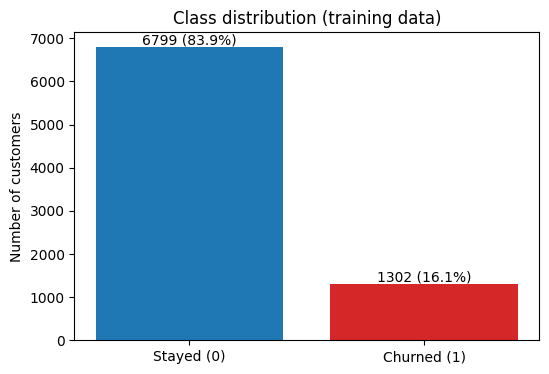

Imbalance ratio (stayed : churned) = 5.2 : 1


In [16]:
# 1. Class distribution - bar chart
counts = y_train.value_counts().sort_index()
plt.figure(figsize=(6, 4))
bars = plt.bar(["Stayed (0)", "Churned (1)"], counts.values, color=["tab:blue", "tab:red"])
for b, v in zip(bars, counts.values):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v} ({v / counts.sum():.1%})", ha="center", va="bottom")
plt.title("Class distribution (training data)"); plt.ylabel("Number of customers"); plt.show()
print("Imbalance ratio (stayed : churned) = {:.1f} : 1".format(counts[0] / counts[1]))



In [17]:
# 2. Basic statistics for the numeric features
num_cols = X_train.select_dtypes("number").columns
display(X_train[num_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Customer_Age,8101.0,46.39,7.99,26.0,41.00,46.00,52.00,73.00
Dependent_count,8101.0,2.35,1.30,0.0,1.00,2.00,3.00,5.00
Months_on_book,8101.0,36.01,7.93,13.0,32.00,36.00,40.00,56.00
Total_Relationship_Count,8101.0,3.81,1.55,1.0,3.00,4.00,5.00,6.00
Months_Inactive_12_mon,8101.0,2.35,1.01,0.0,2.00,2.00,3.00,6.00
Contacts_Count_12_mon,8101.0,2.46,1.11,0.0,2.00,2.00,3.00,6.00
Credit_Limit,8101.0,8580.07,9032.36,1438.3,2562.00,4532.00,10973.00,34516.00
Total_Revolving_Bal,8101.0,1167.67,814.76,0.0,411.00,1289.00,1786.00,2517.00
Avg_Open_To_Buy,8101.0,7412.40,9032.33,10.0,1329.00,3454.00,9750.00,34516.00
Total_Amt_Chng_Q4_Q1,8101.0,0.76,0.22,0.0,0.63,0.74,0.86,3.40


In [18]:
# 3. Hidden missing values: "Unknown" in the text columns
cat_cols = X_train.select_dtypes(exclude="number").columns
print("'Unknown' counts (train):")
print((X_train[cat_cols] == "Unknown").sum())

'Unknown' counts (train):
Gender                0
Education_Level    1207
Marital_Status      605
Income_Category     886
Card_Category         0
dtype: int64


In [19]:
# 4. Category values
for c in cat_cols:
    print(f"\n{c}:\n{X_train[c].value_counts().to_string()}")


Gender:
Gender
F    4272
M    3829

Education_Level:
Education_Level
Graduate         2482
High School      1650
Unknown          1207
Uneducated       1183
College           796
Post-Graduate     427
Doctorate         356

Marital_Status:
Marital_Status
Married     3755
Single      3142
Unknown      605
Divorced     599

Income_Category:
Income_Category
Less than $40K    2832
$40K - $60K       1450
$80K - $120K      1209
$60K - $80K       1136
Unknown            886
$120K +            588

Card_Category:
Card_Category
Blue        7559
Silver       431
Gold          94
Platinum      17


In [20]:
# 5. How churners differ: average of each numeric feature by class
display(train_df.groupby("Churn")[num_cols].mean().T.round(2).rename(columns={0: "Stayed", 1: "Churned"}))

Churn,Stayed,Churned
Customer_Age,46.33,46.71
Dependent_count,2.33,2.44
Months_on_book,35.98,36.15
Total_Relationship_Count,3.92,3.25
Months_Inactive_12_mon,2.28,2.71
Contacts_Count_12_mon,2.36,2.98
Credit_Limit,8674.83,8085.23
Total_Revolving_Bal,1263.07,669.50
Avg_Open_To_Buy,7411.76,7415.73
Total_Amt_Chng_Q4_Q1,0.77,0.69


### Interpretation: Data Exploration

Class distribution:
The bar chart shows 6,799 customers who stayed (83.9%) and 1,302 who churned (16.1%) in the training data, an imbalance ratio of 5.2 to 1. A model trained on this data may lean towards predicting "stayed", because that is correct most of the time.

Basic statistics:
- Customers are between 26 and 73 years old (mean 46) and have been with the bank for 13 to 56 months.
- Credit_Limit ranges from about 1,400 to 34,500 and is right-skewed (mean 8,580, median 4,532), because a small group has very high limits.
- Total_Trans_Amt ranges from 530 to 17,995, and Total_Trans_Ct from 10 to 139 transactions per year.
- Avg_Open_To_Buy is almost the same information as Credit_Limit minus Total_Revolving_Bal (they have the same standard deviation, 9,032), so these features overlap.

How churners differ:
- Churners make far fewer transactions (44.6 compared with 68.6) and spend less (3,041 compared with 4,646).
- They carry about half the revolving balance (670 compared with 1,263) and use half as much of their credit limit (utilization 0.16 compared with 0.30).
- Their activity dropped more between the first and last quarter (transaction count change of 0.55 compared with 0.74), which is an early warning sign.
- They hold fewer bank products (3.25 compared with 3.92), had more inactive months (2.71 compared with 2.28) and contacted the bank more often (2.98 compared with 2.36).
- Age, number of dependents and months as a customer are almost the same for both groups.
Overall, churners are customers who are gradually using their card less before they leave.

Hidden missing values:
The value "Unknown" appears in Education_Level (1,207 customers, 14.9%), Income_Category (886, 10.9%) and Marital_Status (605, 7.5%). Dropping these customers would remove a large part of the data, and filling them with the most common value would invent information. I will keep "Unknown" as its own category. Not sharing this information could itself be a pattern.

Categories:
Most customers have a Blue card (7,559). Silver (431), Gold (94) and especially Platinum (17) are rare.

## Step 5: Encoding the Categorical Features

In [21]:
X_train_enc = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test_enc = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

print("Features after encoding:", X_train_enc.shape[1])
print("Same columns in train and test:", list(X_train_enc.columns) == list(X_test_enc.columns))

Features after encoding: 32
Same columns in train and test: True


### Interpretation: Encoding

I used one-hot encoding with drop_first=True for the 5 categorical columns. This turned the 19 original features into 32: the 14 numeric features plus 18 new 0/1 columns (1 for Gender, 6 for Education_Level, 3 for Marital_Status, 5 for Income_Category and 3 for Card_Category). "Unknown" became its own column where it appeared, so the model can learn whether missing information is linked to churn. The test set has exactly the same columns as the training set. I did not scale the features, because Random Forest splits on thresholds and is not affected by feature scales.

## Step 6: Baseline Model – Random Forest Without Balancing

=== RF Baseline (no balancing) ===
              precision    recall  f1-score   support

      Stayed       0.96      0.99      0.97      1701
     Churned       0.94      0.77      0.85       325

    accuracy                           0.96      2026
   macro avg       0.95      0.88      0.91      2026
weighted avg       0.95      0.96      0.95      2026



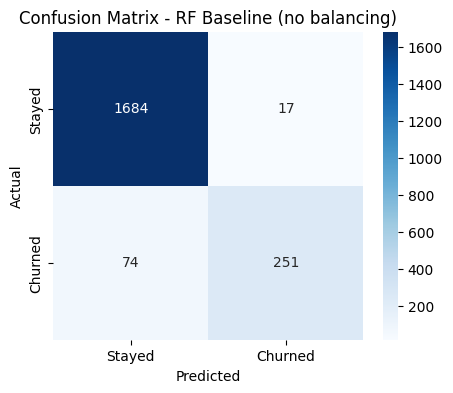

                     Model  Train rows  Train churn %  Accuracy  Precision  Recall    F1  ROC-AUC  PR-AUC
RF Baseline (no balancing)        8101           16.1     0.955      0.937   0.772 0.847    0.984   0.941


In [22]:
results, probs = [], {}

def evaluate(name, model, X_tr, y_tr):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_test_enc)
    prob = model.predict_proba(X_test_enc)[:, 1]
    probs[name] = prob
    results.append({"Model": name,
                    "Train rows": len(y_tr), "Train churn %": round(y_tr.mean() * 100, 1),
                    "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred),
                    "Recall": recall_score(y_test, pred),
                    "F1": f1_score(y_test, pred),
                    "ROC-AUC": roc_auc_score(y_test, prob),
                    "PR-AUC": average_precision_score(y_test, prob)})
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))
    cm = confusion_matrix(y_test, pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion Matrix - {name}"); plt.show()

rf_base = RandomForestClassifier(random_state=random_seed, n_jobs=-1)
evaluate("RF Baseline (no balancing)", rf_base, X_train_enc, y_train)
print(pd.DataFrame(results).round(3).to_string(index=False))

### Interpretation: Baseline Random Forest (No Balancing)

The baseline Random Forest reached 95.5% accuracy. This is clearly better than the 83.9% a model would get by always predicting "stayed", so the model has learned real patterns. But accuracy hides how it performs on the minority class.

Confusion matrix:
- 1,684 customers who stayed were correctly identified, and only 17 were wrongly flagged as churners (false positives).
- 251 of the 325 churners were caught (true positives), but 74 churners were missed (false negatives).

Churn class metrics:
- Precision is 0.937: when the model predicts a customer will churn, it is right about 94% of the time.
- Recall is 0.772: it finds only about 77% of the real churners, so almost 1 in 4 is missed.
- The F1-score is 0.847.
- ROC-AUC is 0.984 and PR-AUC (average precision) is 0.941, so the model ranks churners very well. Its default 0.5 threshold is cautious, though.

Because churners are only 16% of the training data, the model leans towards predicting "stayed". It makes very few false alarms, but it misses 74 customers who will leave. For a bank, a missed churner is a lost customer, which usually costs more than contacting a customer who would have stayed. In the next steps I will try SMOTE and class weights to improve recall.

## Step 7: Apply SMOTE to the Training Data and Retrain the Random Forest

Before SMOTE: {0: 6799, 1: 1302} | total: 8101
After SMOTE:  {0: 6799, 1: 6799} | total: 13598
Synthetic churners created: 5497
Test set unchanged: {0: 1701, 1: 325}
=== RF + SMOTE ===
              precision    recall  f1-score   support

      Stayed       0.96      0.97      0.97      1701
     Churned       0.84      0.81      0.83       325

    accuracy                           0.95      2026
   macro avg       0.90      0.89      0.90      2026
weighted avg       0.94      0.95      0.94      2026



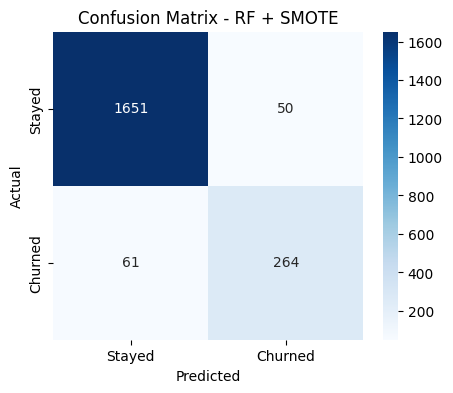

                     Model  Train rows  Train churn %  Accuracy  Precision  Recall    F1  ROC-AUC  PR-AUC
RF Baseline (no balancing)        8101           16.1     0.955      0.937   0.772 0.847    0.984   0.941
                RF + SMOTE       13598           50.0     0.945      0.841   0.812 0.826    0.982   0.917


In [23]:
smote = SMOTE(random_state=random_seed)
X_train_smote, y_train_smote = smote.fit_resample(X_train_enc, y_train)

print("Before SMOTE:", y_train.value_counts().sort_index().to_dict(), "| total:", len(y_train))
print("After SMOTE: ", y_train_smote.value_counts().sort_index().to_dict(), "| total:", len(y_train_smote))
print("Synthetic churners created:", len(y_train_smote) - len(y_train))
print("Test set unchanged:", y_test.value_counts().sort_index().to_dict())

rf_smote = RandomForestClassifier(random_state=random_seed, n_jobs=-1)
evaluate("RF + SMOTE", rf_smote, X_train_smote, y_train_smote)
print(pd.DataFrame(results).round(3).to_string(index=False))

### Interpretation: Random Forest with SMOTE

SMOTE created 5,497 synthetic churners in the training data, so the training set grew from 8,101 to 13,598 customers with exactly 50% in each class (6,799 stayed and 6,799 churned). The test set was not changed and still has the real churn rate (1,701 stayed and 325 churned).

Results compared with the baseline:
- Recall improved from 0.772 to 0.812: the model caught 264 churners instead of 251, and missed 61 instead of 74.
- Precision dropped from 0.937 to 0.841: false alarms rose from 17 to 50.
- The F1-score dropped slightly, from 0.847 to 0.826, and accuracy from 95.5% to 94.5%.
- ROC-AUC (0.982) and PR-AUC (0.917) were slightly lower than the baseline (0.984 and 0.941).

SMOTE made the model more willing to predict churn, which helped it find more churners but also created more false alarms. Because ROC-AUC and PR-AUC did not improve, the model did not get better at separating churners from non-churners; it mainly moved its decision point. A possible reason is that SMOTE also interpolates the 0/1 encoded columns, creating unrealistic synthetic customers (for example, values between 0 and 1 for gender). Overall, SMOTE is useful if catching more churners matters more than avoiding false alarms, but it is not a clear improvement on this dataset.

## Step 8: Train the Random Forest with Class Weights

'balanced' weights -> stayed (0): 0.6 | churned (1): 3.11
=== RF + Class Weights (balanced) ===
              precision    recall  f1-score   support

      Stayed       0.95      0.99      0.97      1701
     Churned       0.94      0.74      0.83       325

    accuracy                           0.95      2026
   macro avg       0.95      0.86      0.90      2026
weighted avg       0.95      0.95      0.95      2026



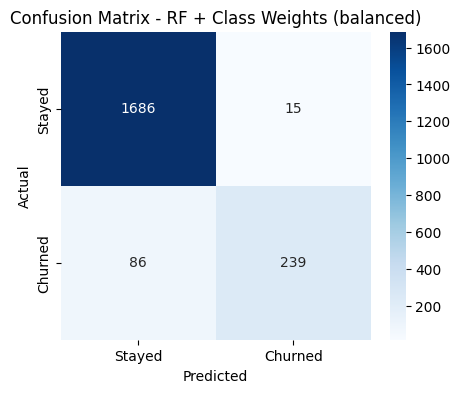

=== RF + Class Weights (balanced_subsample) ===
              precision    recall  f1-score   support

      Stayed       0.95      0.99      0.97      1701
     Churned       0.93      0.73      0.82       325

    accuracy                           0.95      2026
   macro avg       0.94      0.86      0.89      2026
weighted avg       0.95      0.95      0.94      2026



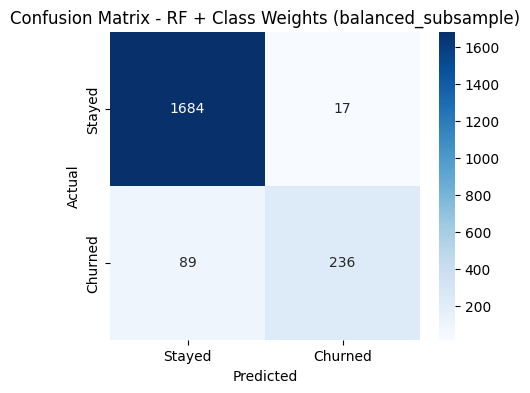

                                  Model  Train rows  Train churn %  Accuracy  Precision  Recall    F1  ROC-AUC  PR-AUC
             RF Baseline (no balancing)        8101           16.1     0.955      0.937   0.772 0.847    0.984   0.941
                             RF + SMOTE       13598           50.0     0.945      0.841   0.812 0.826    0.982   0.917
          RF + Class Weights (balanced)        8101           16.1     0.950      0.941   0.735 0.826    0.984   0.938
RF + Class Weights (balanced_subsample)        8101           16.1     0.948      0.933   0.726 0.817    0.985   0.935


In [24]:
weights = len(y_train) / (2 * np.bincount(y_train))
print("'balanced' weights -> stayed (0):", round(weights[0], 2), "| churned (1):", round(weights[1], 2))

rf_weighted = RandomForestClassifier(class_weight="balanced", random_state=random_seed, n_jobs=-1)
evaluate("RF + Class Weights (balanced)", rf_weighted, X_train_enc, y_train)

rf_weighted_sub = RandomForestClassifier(class_weight="balanced_subsample", random_state=random_seed, n_jobs=-1)
evaluate("RF + Class Weights (balanced_subsample)", rf_weighted_sub, X_train_enc, y_train)

print(pd.DataFrame(results).round(3).to_string(index=False))

### Interpretation: Random Forest with Class Weights

With class_weight="balanced", each churner counted about 3.11 and each customer who stayed about 0.6, so a mistake on a churner cost about 5 times more during training.

Results:
- Balanced weights: 239 churners caught and 86 missed (recall 0.735), with only 15 false alarms (precision 0.941). F1 is 0.826, ROC-AUC 0.984 and PR-AUC 0.938.
- Balanced_subsample (weights recalculated in each tree's bootstrap sample): 236 caught and 89 missed (recall 0.726), with 17 false alarms (precision 0.933). F1 is 0.817, ROC-AUC 0.985 and PR-AUC 0.935.

Surprisingly, class weights made recall slightly worse than the baseline (0.772), even though their purpose is to focus on the minority class. Random Forest grows very deep trees by default, and their leaves end up almost pure, so the weights have little effect on the final predictions. Here they made the model slightly more cautious. ROC-AUC stayed about the same (0.984 to 0.985), so the model's ability to rank churners did not change.

So far, SMOTE gives the highest recall (0.812) and catches the most churners, while the baseline gives the best overall balance (F1 0.847 and PR-AUC 0.941). Class weights did not help on this dataset.

## Step 9: Comparison of Performance Metrics – ROC-AUC

                                  Model  Accuracy  Precision  Recall    F1  ROC-AUC  PR-AUC
             RF Baseline (no balancing)     0.955      0.937   0.772 0.847    0.984   0.941
                             RF + SMOTE     0.945      0.841   0.812 0.826    0.982   0.917
          RF + Class Weights (balanced)     0.950      0.941   0.735 0.826    0.984   0.938
RF + Class Weights (balanced_subsample)     0.948      0.933   0.726 0.817    0.985   0.935


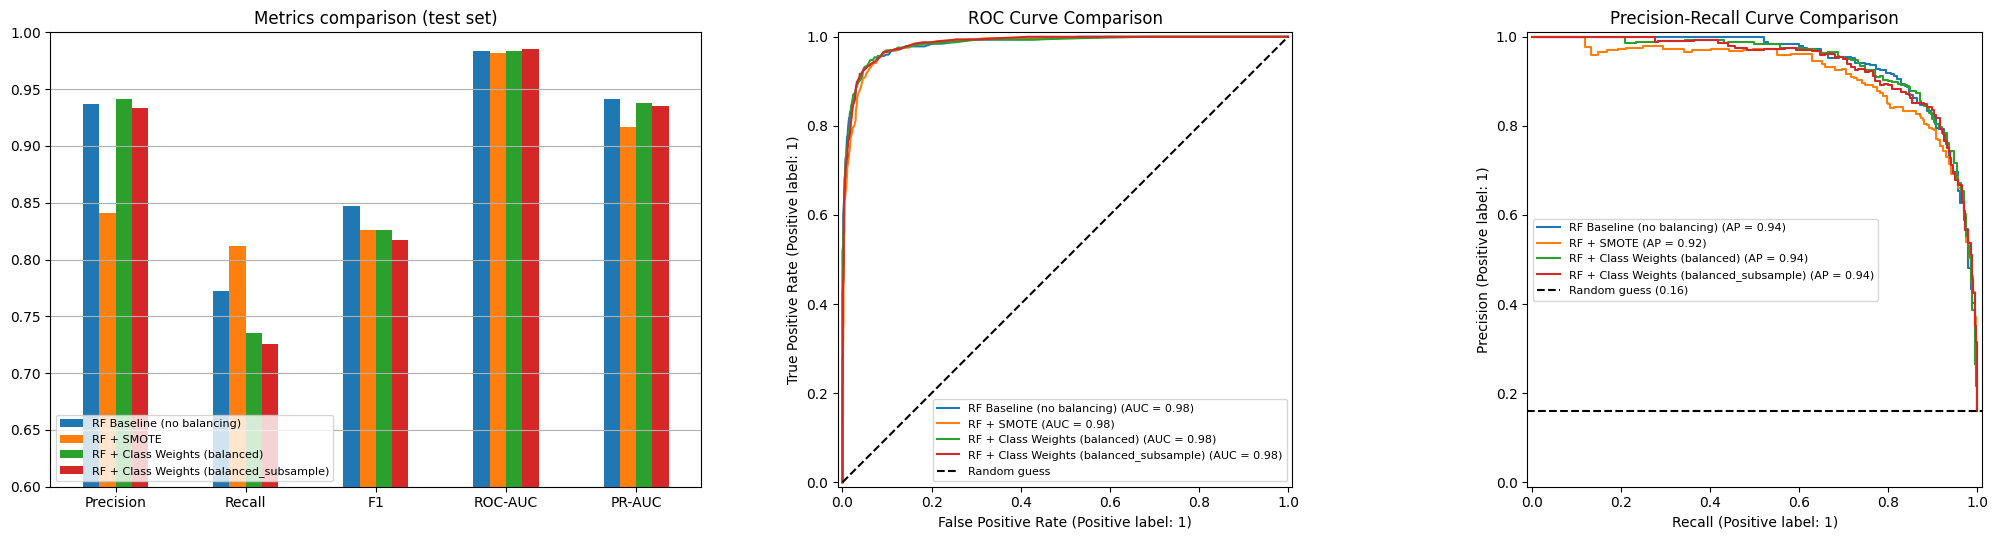

In [26]:
compare = pd.DataFrame(results).round(3)
print(compare.drop(columns=["Train rows", "Train churn %"]).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))

# 1. Bar chart of the metrics
compare.set_index("Model")[["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]].T.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_ylim(0.6, 1.0); axes[0].set_title("Metrics comparison (test set)")
axes[0].legend(fontsize=8, loc="lower left"); axes[0].grid(axis="y")

# 2. ROC curves (the comparison the assignment asks for)
for name, prob in probs.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("ROC Curve Comparison"); axes[1].legend(fontsize=8)

# 3. Precision-Recall curves (better for imbalanced data)
for name, prob in probs.items():
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=axes[2])
axes[2].axhline(y_test.mean(), color="k", linestyle="--", label=f"Random guess ({y_test.mean():.2f})")
axes[2].set_title("Precision-Recall Curve Comparison"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()


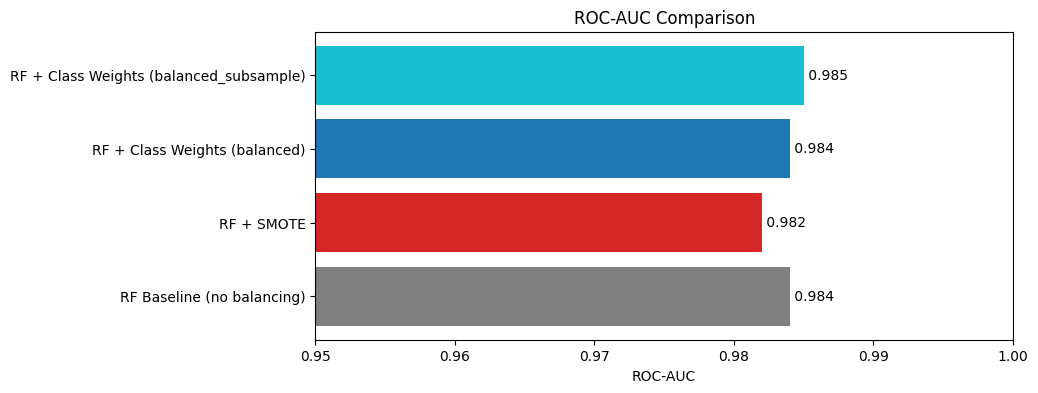

In [27]:
# ROC-AUC bar chart on its own (the assignment's required plot)
plt.figure(figsize=(9, 4))
auc_vals = compare.set_index("Model")["ROC-AUC"]
bars = plt.barh(auc_vals.index, auc_vals.values, color=["gray", "tab:red", "tab:blue", "tab:cyan"])
for b, v in zip(bars, auc_vals.values):
    plt.text(v, b.get_y() + b.get_height() / 2, f" {v:.3f}", va="center")
plt.xlim(0.95, 1.0); plt.xlabel("ROC-AUC"); plt.title("ROC-AUC Comparison"); plt.show()

### Interpretation: Performance Comparison

ROC-AUC comparison:
All four models have very similar ROC-AUC scores: 0.984 (baseline), 0.982 (SMOTE), 0.984 (balanced class weights) and 0.985 (balanced_subsample). The ROC curves lie almost on top of each other, close to the top-left corner. The difference between the best and worst model is only 0.003, so in terms of ROC-AUC the four models are essentially tied. All of them separate churners from non-churners very well.

Precision-Recall curves:
The PR curves are also very close. SMOTE's curve is slightly lower in the high-precision area, which matches its lower PR-AUC (0.917 compared with about 0.94 for the others). All curves are far above the random-guess line at 0.16 (the churn rate).

Metrics comparison:
The main differences are in precision and recall at the default threshold of 0.5:
- SMOTE has the highest recall (0.812) but the lowest precision (0.841).
- The baseline has the best balance (F1 0.847).
- The class-weight models have the highest precision (0.933 to 0.941) but the lowest recall (0.726 to 0.735).

The balancing techniques did not make the Random Forest better at distinguishing churners (ROC-AUC and PR-AUC did not improve). They only changed where the model draws the line between "churn" and "stay". This suggests that choosing the decision threshold directly (threshold moving) could be a simpler way to balance catching churners against false alarms.

## Step 11: Report – Handling Imbalanced Data for Customer Churn

### Dataset and approach
The provided churn file was almost balanced (about 53% / 47%) and was perfectly predicted by a basic Random Forest, so I used the Credit Card Customers dataset from Kaggle instead (10,127 customers, 19 features after cleaning). Only 16.1% of customers churned, an imbalance of about 5 to 1. I removed two leakage columns (Naive_Bayes_Classifier_...) and the customer ID, kept "Unknown" as its own category, one-hot encoded the categorical features, and split the data 80/20 with stratification. The test set (325 churners out of 2,026 customers) was never resampled, so every model was tested on the real churn rate.

### Results

| Model | Training data | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| RF Baseline (no balancing) | 8,101 rows, 16% churn | 0.937 | 0.772 | **0.847** | 0.984 | **0.941** |
| RF + SMOTE | 13,598 rows, 50% churn | 0.841 | **0.812** | 0.826 | 0.982 | 0.917 |
| RF + Class Weights (balanced) | 8,101 rows, weighted | **0.941** | 0.735 | 0.826 | 0.984 | 0.938 |
| RF + Class Weights (balanced_subsample) | 8,101 rows, weighted | 0.933 | 0.726 | 0.817 | **0.985** | 0.935 |

Missed churners (false negatives): baseline 74, SMOTE 61, balanced 86, balanced_subsample 89.
False alarms (false positives): baseline 17, SMOTE 50, balanced 15, balanced_subsample 17.

### Discussion
**Accuracy is misleading:** a model that always predicts "stayed" would score 83.9% accuracy while catching zero churners. All my models scored about 95% accuracy, so I compared them mainly on recall, precision, F1-score, ROC-AUC and PR-AUC.

**Baseline:** even without balancing, Random Forest performed well (F1 0.847, ROC-AUC 0.984), but it was cautious: it missed 74 of 325 churners (recall 0.772).

**SMOTE:** creating 5,497 synthetic churners made the model more willing to predict churn. Recall rose to 0.812 (13 more churners caught), but false alarms nearly tripled (17 to 50), and F1 and PR-AUC dropped slightly.

**Class weights:** surprisingly, class weights slightly lowered recall (0.735 and 0.726). Random Forest grows very deep trees whose leaves are almost pure, so the weights had little effect and made the model slightly more cautious.

**ROC-AUC comparison:** all four models had almost the same ROC-AUC (0.982 to 0.985), and their ROC curves overlapped. The balancing techniques did not make the model better at separating churners from non-churners; they mainly changed where the model draws the line between "churn" and "stay".

### Recommendation
The best model depends on the business goal:
- If the bank's priority is to catch as many churners as possible (for example, because a lost customer is much more costly than a retention call), **RF + SMOTE** is the best choice. It missed the fewest churners (61).
- If false alarms are costly (for example, expensive retention offers), the **baseline Random Forest** gives the best overall balance (highest F1 and PR-AUC).
Because all models rank customers almost equally well, a simpler next step would be threshold moving: lowering the baseline model's decision threshold to catch more churners, with no synthetic data.

### Challenges
1. The provided dataset was balanced and too easy, so I had to find a suitable imbalanced dataset.
2. Two columns in the new dataset were predictions from another model built using the target (leakage), so I removed them.
3. Three categorical columns had hidden missing values recorded as "Unknown" (7.5% to 14.9% of customers). I kept them as a separate category.
4. SMOTE also interpolates the encoded 0/1 columns, creating some unrealistic synthetic customers. SMOTENC, a version designed for mixed data, could handle this better.
5. Class weights had little effect on fully grown Random Forest trees. Limiting tree depth or tuning the weights could change this.